# Round 2: relabel with round 1's best model, then a new baseline

1. **Relabel** every captcha with `v1/models/captcha_cnn_ft_650.pt` (gold 93.42%) → `labels_v2.csv`.
2. **Train** a new baseline from scratch on those labels (plus your reviews as true labels).
3. **Test** on gold, **save**, then **review + fine-tune** it like round 1.

Gold (`../data/gold.csv`, 152 hand-checked) is never relabeled, reviewed or trained on: it's the test, so scores
compare directly with round 1 (baseline 86.84%, fine-tuned 93.42%). Run the cells top to bottom; skip none.

## 1. Setup and paths

In [1]:
import csv, json, math, os, random, time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

IMAGES = "../data/varun"                     # raw captchas, <id>.png (never modified)
GOLD_CSV = "../data/gold.csv"                # 152 hand-checked captchas: the test set, never trained on
REVIEWS = "../data/reviews.json"             # your hand-checked model reads (review.py adds to it)
VISION_LABELS = "../v1/labels_vision.csv"    # every image id + Vision's read (for reference)
RELABEL_MODEL = "../v1/models/captcha_cnn_ft_650.pt"   # best model so far: gold 93.42%
LABELS_CSV = "labels_v2.csv"                 # written by the relabel cell
CACHE = "cache/all_images.npz"               # decoded images, so re-runs skip reading 127k PNGs
MODEL_PATH = "models/captcha_cnn_v2.pt"      # the new baseline
FT_PATH = "models/captcha_cnn_v2_ft.pt"      # the new baseline fine-tuned on your reviews
os.makedirs("models", exist_ok=True)
os.makedirs("cache", exist_ok=True)

SEED = 0
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

_teacher = torch.load(RELABEL_MODEL, map_location="cpu")
ALPHABET, LENGTH = _teacher["alphabet"], _teacher["length"]   # same classes as round 1 and the extension
CHAR_TO_IDX = {c: i for i, c in enumerate(ALPHABET)}
print("device:", DEVICE, "| alphabet:", ALPHABET)

device: mps | alphabet: 2345689ABDEFGHJLMNQRTYabdefghijmnqrty


/Users/varunmatta/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load all images and gold (cached after the first run, ~1–2 min)

In [2]:
with open(VISION_LABELS) as f:
    VISION = {r["id"]: r["label"] for r in csv.DictReader(f)}   # Vision's read; "" where it gave up
ALL_IDS = np.array(sorted(VISION, key=int))

def read_gray(i):
    return np.array(Image.open(os.path.join(IMAGES, f"{i}.png")).convert("L"))

cached = np.load(CACHE) if os.path.exists(CACHE) else None
if cached is not None and np.array_equal(cached["ids"], ALL_IDS):
    imgs = cached["imgs"]
else:
    t = time.time()
    with ThreadPoolExecutor(8) as ex:
        imgs = np.stack(list(ex.map(read_gray, ALL_IDS)))
    np.savez(CACHE, ids=ALL_IDS, imgs=imgs)
    print(f"read {len(imgs)} images in {time.time() - t:.0f}s")
H, W = imgs.shape[1:]
X = torch.from_numpy(imgs).to(DEVICE)   # uint8, all images on the GPU (~0.9 GB)
row_of = {i: k for k, i in enumerate(ALL_IDS)}

with open(GOLD_CSV) as f:
    GOLD = {r["id"]: r for r in csv.DictReader(f)}
assert all(i in row_of for i in GOLD)
print("images:", imgs.shape, "| gold:", len(GOLD))

read 126919 images in 10s
images: (126919, 45, 150) | gold: 152


## 3. Model definition and helpers (same network as round 1)

In [3]:
class CaptchaCNN(nn.Module):
    def __init__(self, n_classes, length=LENGTH, widths=(32, 64, 128, 192), dropout=0.3):
        super().__init__()
        layers, c_in = [], 1
        for c in widths:   # each block halves H and W: 45x150 -> 2x9
            layers += [
                nn.Conv2d(c_in, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            ]
            c_in = c
        self.features = nn.Sequential(*layers)
        n_cols = W // 2 ** len(widths)   # 9 columns left, kept apart so heads know left from right
        self.shared = nn.Sequential(nn.Flatten(), nn.Dropout(dropout),
                                    nn.Linear(c_in * n_cols, 512), nn.ReLU(inplace=True), nn.Dropout(dropout))
        self.heads = nn.ModuleList(nn.Linear(512, n_classes) for _ in range(length))

    def forward(self, x):
        z = self.features(x).mean(dim=2)   # average over height -> (B, C, columns)
        z = self.shared(z)
        return torch.stack([head(z) for head in self.heads], dim=1)   # (B, LENGTH, n_classes)

def to_input(x):
    """uint8 (B, H, W) -> float (B, 1, H, W) with ink = 1, paper = 0."""
    return (1 - x.float() / 255).unsqueeze(1)

def load_model(path):
    ckpt = torch.load(path, map_location=DEVICE)
    m = CaptchaCNN(len(ckpt["alphabet"]), ckpt["length"], ckpt["widths"], ckpt["config"]["dropout"]).to(DEVICE)
    m.load_state_dict(ckpt["state_dict"])
    return m.eval(), ckpt

@torch.no_grad()
def model_reads(m, ids, batch_size=2048):
    """Model reads + weakest-character confidence for a list of image ids."""
    m.eval()
    reads, confs = [], []
    for k in range(0, len(ids), batch_size):
        x = to_input(X[torch.tensor([row_of[i] for i in ids[k:k + batch_size]]).to(DEVICE)])
        conf, idx = m(x).softmax(-1).max(-1)
        reads += ["".join(ALPHABET[j] for j in p) for p in idx.cpu().tolist()]
        confs += conf.min(-1).values.cpu().tolist()
    return reads, confs

print(f"{sum(p.numel() for p in CaptchaCNN(len(ALPHABET)).parameters()) / 1e6:.2f}M parameters")

1.82M parameters


## 4. Relabel every captcha with the best model (~30 s)

In [4]:
%run -i ../scripts/relabel.py

wrote labels_v2.csv: 126117 model labels + 650 your reviews (gold's 152 left out)
relabel model captcha_cnn_ft_650.pt on gold: 142/152 = 93.42% (the teacher's score; the new baseline should beat it)
model label differs from Vision's on 25062 images
  confidence < 0.3:      8 images (0.0%)
  confidence < 0.4:    113 images (0.1%)
  confidence < 0.5:   1899 images (1.5%)
  confidence < 0.6:   5424 images (4.3%)


## 5. Labels and splits
Model labels split 70/20/10 into train / test / val; your reviews (true labels) all go to train; gold stays apart.
Val and test now measure agreement with the teacher model, so they read high: only **gold** is the real score.

In [5]:
MIN_CONF = 0.0   # drop model labels less confident than this (0 = keep all); see the relabel printout

with open(LABELS_CSV) as f:
    rows = list(csv.DictReader(f))
assert not any(r["id"] in GOLD for r in rows), "a gold captcha is in the training labels"
auto = [r for r in rows if r["source"] == "model" and float(r["confidence"]) >= MIN_CONF]
reviewed = [r for r in rows if r["source"] == "review"]
random.Random(SEED).shuffle(auto)
n_train, n_test = int(0.7 * len(auto)), int(0.2 * len(auto))
split_rows = {
    "train": auto[:n_train] + reviewed,
    "test": auto[n_train:n_train + n_test],
    "val": auto[n_train + n_test:],
    "gold": [{"id": i, "label": g["label"]} for i, g in GOLD.items()],
}

def encode(label):
    return [CHAR_TO_IDX[c] for c in label]

def decode_pred(p):
    return "".join(ALPHABET[i] for i in p)

data = {name: (torch.tensor([row_of[r["id"]] for r in rs]), torch.tensor([encode(r["label"]) for r in rs]))
        for name, rs in split_rows.items()}
print({k: len(v) for k, v in split_rows.items()}, f"(train includes {len(reviewed)} reviews)")

{'train': 88931, 'test': 25223, 'val': 12613, 'gold': 152} (train includes 650 reviews)


## 6. Batching and augmentation (preview: originals on top, augmented below)

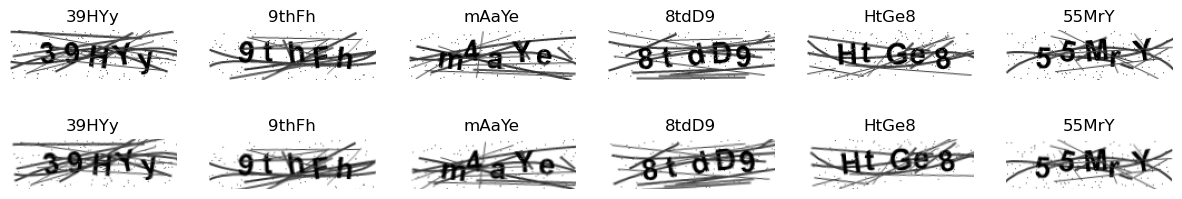

In [6]:
def batches(split, batch_size, shuffle):
    idx, y = data[split]
    order = torch.randperm(len(idx)) if shuffle else torch.arange(len(idx))
    for k in range(0, len(idx), batch_size):
        j = order[k:k + batch_size]
        yield to_input(X[idx[j].to(DEVICE)]), y[j].to(DEVICE)

def augment(x, max_shift=4, max_rot=4):
    """Random shift (px) and rotation (degrees) per image, whole batch at once on the GPU.
    No flips: a mirrored letter is a different letter."""
    b, _, h, w = x.shape
    rnd = lambda: torch.rand(b, device=x.device) * 2 - 1
    ang = rnd() * max_rot * math.pi / 180
    cos, sin = torch.cos(ang), torch.sin(ang)
    tx, ty = rnd() * max_shift * 2 / w, rnd() * max_shift * 2 / h
    theta = torch.stack([torch.stack([cos, -sin * h / w, tx], 1),
                         torch.stack([sin * w / h, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, padding_mode="zeros", align_corners=False)

x, y = next(batches("train", 6, shuffle=True))
fig, ax = plt.subplots(2, 6, figsize=(15, 2.6))
for k, img in enumerate(torch.cat([x, augment(x)]).cpu()):
    ax[k // 6, k % 6].imshow(img[0], cmap="gray_r", vmin=0, vmax=1)
    ax[k // 6, k % 6].set_title(decode_pred(y[k % 6].tolist()))
    ax[k // 6, k % 6].axis("off")
plt.show()

## 7. Training and evaluation functions

In [7]:
@torch.no_grad()
def predict(model, split, batch_size=1024):
    model.eval()
    return torch.cat([model(x).argmax(-1).cpu() for x, _ in batches(split, batch_size, shuffle=False)])

def evaluate(model, split):
    p, y = predict(model, split), data[split][1]
    return {"exact": (p == y).all(1).float().mean().item(), "char": (p == y).float().mean().item()}

def train(cfg, tag=""):
    """Trains with cfg; keeps the epoch with the best val exact-match. Returns (model, best val)."""
    torch.manual_seed(cfg["seed"])
    model = CaptchaCNN(len(ALPHABET), dropout=cfg["dropout"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    steps_per_epoch = math.ceil(len(data["train"][0]) / cfg["batch"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], total_steps=cfg["epochs"] * steps_per_epoch)
    best, best_state, stale = -1.0, None, 0
    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        t, total = time.time(), torch.zeros((), device=DEVICE)
        bar = tqdm(batches("train", cfg["batch"], shuffle=True), total=steps_per_epoch,
                   desc=f"{tag}epoch {epoch}/{cfg['epochs']}", leave=False)
        for step, (x, y) in enumerate(bar, 1):
            if cfg["augment"]:
                x = augment(x)
            loss = F.cross_entropy(model(x).flatten(0, 1), y.flatten(), label_smoothing=cfg["smoothing"])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            total += loss.detach()
            if step % 50 == 0:   # reading the loss forces a GPU sync, so only now and then
                bar.set_postfix(loss=f"{total.item() / step:.3f}")
        val = evaluate(model, "val")
        gold_r = evaluate(model, "gold")
        print(f"{tag}epoch {epoch:>2}/{cfg['epochs']}  loss {total.item() / steps_per_epoch:.3f}  "
              f"val exact {val['exact']:.2%}  char {val['char']:.2%}  "
              f"gold exact {gold_r['exact']:.2%}  {time.time() - t:.0f}s", flush=True)
        if val["exact"] > best:
            best, stale = val["exact"], 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= cfg["patience"]:
                print(f"{tag}stopping early, no val gain for {stale} epochs")
                break
    model.load_state_dict(best_state)
    return model, best

CFG = dict(epochs=10, batch=256, lr=2e-3, weight_decay=1e-4, dropout=0.3,
           smoothing=0.1, augment=True, patience=4, seed=SEED)

## 8. Train the new baseline (~15 min at ~90 s/epoch)

In [8]:
model, best_val = train(CFG)
print(f"best val exact: {best_val:.2%}")

epoch  1/10  loss 2.738  val exact 76.93%  char 95.00%  gold exact 78.29%  94s


epoch  2/10  loss 0.895  val exact 97.02%  char 99.40%  gold exact 95.39%  95s


epoch  3/10  loss 0.809  val exact 97.72%  char 99.54%  gold exact 94.74%  97s


epoch  4/10  loss 0.785  val exact 97.80%  char 99.56%  gold exact 94.74%  94s


epoch  5/10  loss 0.772  val exact 97.73%  char 99.54%  gold exact 94.08%  95s


epoch  6/10  loss 0.762  val exact 97.78%  char 99.55%  gold exact 94.74%  93s


epoch  7/10  loss 0.754  val exact 98.38%  char 99.67%  gold exact 94.08%  91s


epoch  8/10  loss 0.748  val exact 98.28%  char 99.65%  gold exact 93.42%  91s


epoch  9/10  loss 0.745  val exact 98.34%  char 99.67%  gold exact 94.74%  92s


epoch 10/10  loss 0.742  val exact 98.36%  char 99.67%  gold exact 94.74%  91s
best val exact: 98.38%


## 9. Test: the number to beat is gold 93.42% (round 1 fine-tuned)

val   ( 12613 images)  exact 98.38%  char 99.67%
test  ( 25223 images)  exact 98.18%  char 99.64%
gold  (   152 images)  exact 94.08%  char 98.82%
gold, round 1 fine-tuned (teacher): 93.42%
gold, round 2 baseline: 94.08%
per-position accuracy on gold: ['99.3%', '99.3%', '98.7%', '98.0%', '98.7%']
confusions on gold (true -> predicted): [(('9', 'g'), 3), (('y', 'Y'), 2), (('g', '9'), 1), (('D', 'B'), 1), (('Y', 'y'), 1), (('G', '6'), 1)]


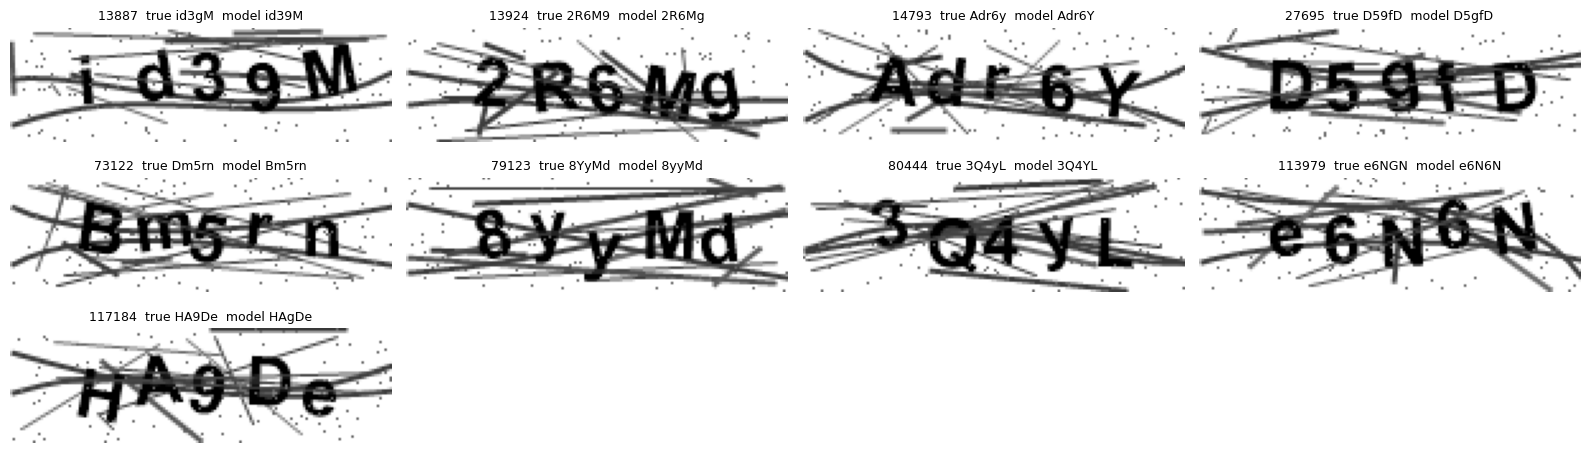

In [9]:
for split in ("val", "test", "gold"):
    r = evaluate(model, split)
    print(f"{split:<5} ({len(data[split][0]):>6} images)  exact {r['exact']:.2%}  char {r['char']:.2%}")

teacher, _ = load_model(RELABEL_MODEL)
for name, m in (("round 1 fine-tuned (teacher)", teacher), ("round 2 baseline", model)):
    print(f"gold, {name}: {evaluate(m, 'gold')['exact']:.2%}")

p_gold, y_gold = predict(model, "gold"), data["gold"][1]
print("per-position accuracy on gold:", [f"{a:.1%}" for a in (p_gold == y_gold).float().mean(0).tolist()])
mix = Counter((ALPHABET[t], ALPHABET[q]) for pp, yy in zip(p_gold, y_gold)
              for t, q in zip(yy.tolist(), pp.tolist()) if t != q)
print("confusions on gold (true -> predicted):", mix.most_common(10))

gold_rows = split_rows["gold"]
wrong = [k for k in range(len(gold_rows)) if not torch.equal(p_gold[k], y_gold[k])]
cols, rows_n = 4, max(1, math.ceil(len(wrong) / 4))
fig, ax = plt.subplots(rows_n, cols, figsize=(16, 1.6 * rows_n), squeeze=False)
for a in ax.flat:
    a.axis("off")
for a, k in zip(ax.flat, wrong):
    a.imshow(imgs[row_of[gold_rows[k]["id"]]], cmap="gray")
    a.set_title(f"{gold_rows[k]['id']}  true {gold_rows[k]['label']}  model {decode_pred(p_gold[k].tolist())}", fontsize=9)
plt.tight_layout()
plt.show()

## 10. Save, reload, check the reload predicts the same

In [10]:
torch.save({
    "state_dict": model.state_dict(),
    "alphabet": ALPHABET,
    "length": LENGTH,
    "image_size": (H, W),
    "widths": (32, 64, 128, 192),
    "config": CFG,
    "trained_on": LABELS_CSV,
    "input": "grayscale HxW, x = 1 - pixel/255 (ink = 1), shape (B, 1, H, W)",
    "scores": {s: evaluate(model, s) for s in ("val", "test", "gold")},
}, MODEL_PATH)

reloaded, ckpt = load_model(MODEL_PATH)
assert torch.equal(predict(reloaded, "gold"), predict(model, "gold")), "reloaded model predicts differently"
print(f"saved {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB), reload OK:", ckpt["scores"])

saved models/captcha_cnn_v2.pt (7.3 MB), reload OK: {'val': {'exact': 0.983826220035553, 'char': 0.9967176914215088}, 'test': {'exact': 0.9818023443222046, 'char': 0.9963604807853699}, 'gold': {'exact': 0.9407894611358643, 'char': 0.9881578683853149}}


step 1 (blind): 152 of 152 gold captchas left to type


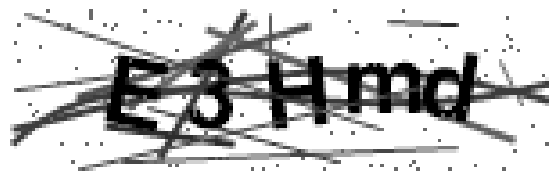

[1/152] 115860  type what you see (s=skip, q=quit):  E3Hmd


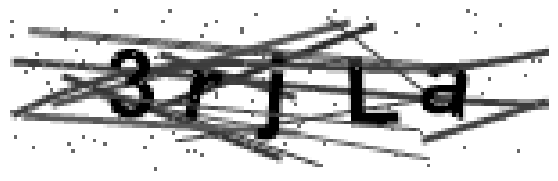

[2/152] 26839  type what you see (s=skip, q=quit):  3rjLa


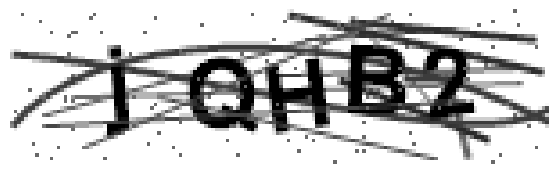

[3/152] 50772  type what you see (s=skip, q=quit):  jQHB2


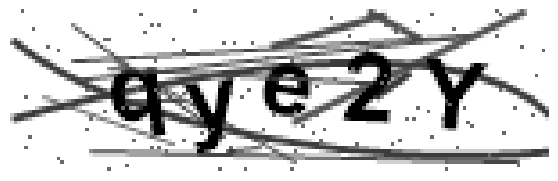

[4/152] 97394  type what you see (s=skip, q=quit):  qye2Y


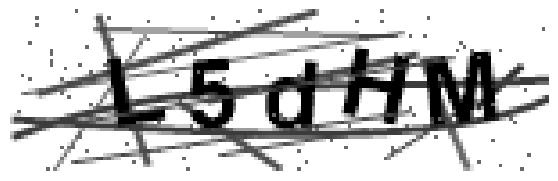

[5/152] 46333  type what you see (s=skip, q=quit):  L5dHM


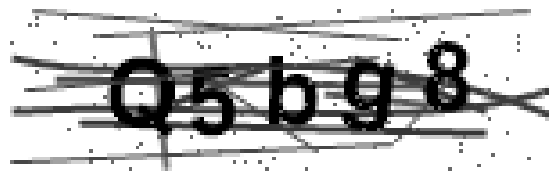

[6/152] 54258  type what you see (s=skip, q=quit):  Q5bg8


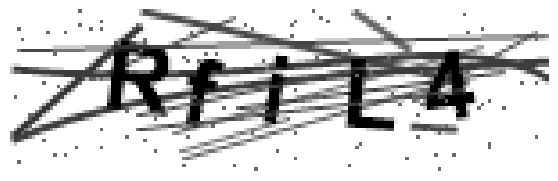

[7/152] 70054  type what you see (s=skip, q=quit):  RfiL4


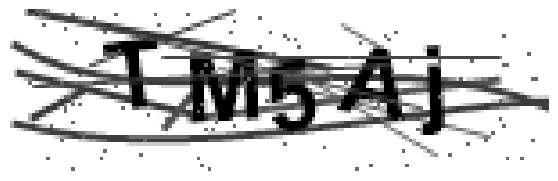

[8/152] 25703  type what you see (s=skip, q=quit):  TM5Aj


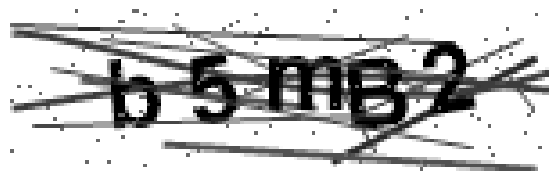

[9/152] 40128  type what you see (s=skip, q=quit):  b5mB2


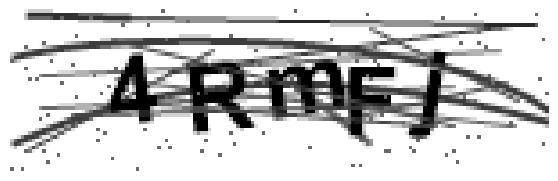

[10/152] 94667  type what you see (s=skip, q=quit):  4RmFj


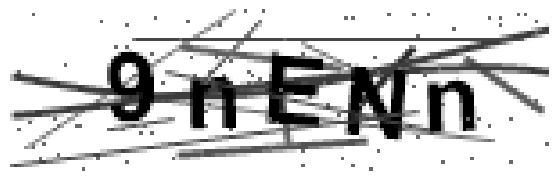

[11/152] 68424  type what you see (s=skip, q=quit):  9nENn


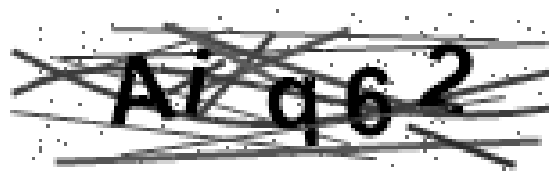

[12/152] 116631  type what you see (s=skip, q=quit):  Aiq62


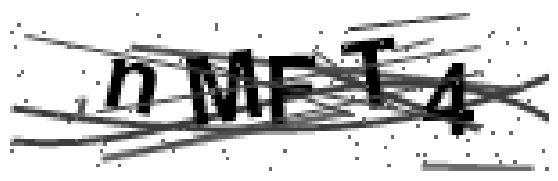

[13/152] 81028  type what you see (s=skip, q=quit):  nMFT4


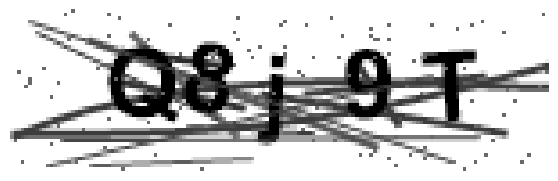

[14/152] 4659  type what you see (s=skip, q=quit):  Q8j9T


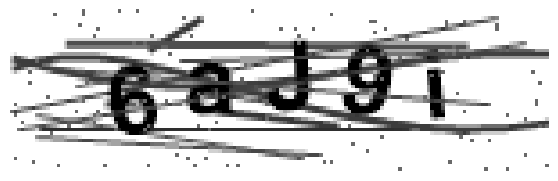

[15/152] 79838  type what you see (s=skip, q=quit):  6aJ9i


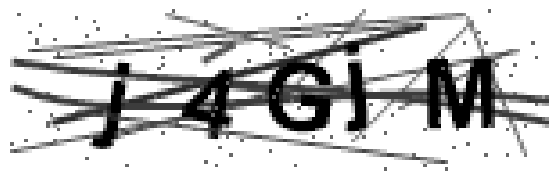

[16/152] 117298  type what you see (s=skip, q=quit):  j4GjM


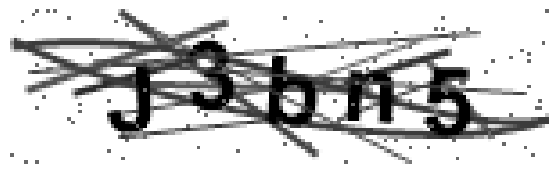

[17/152] 113845  type what you see (s=skip, q=quit):  J3bn5


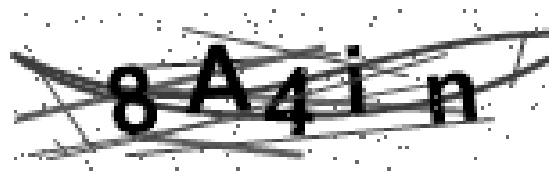

[18/152] 109256  type what you see (s=skip, q=quit):  8A4in


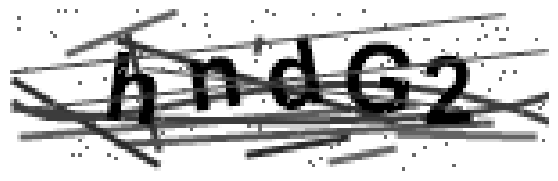

[19/152] 94112  type what you see (s=skip, q=quit):  hndG2


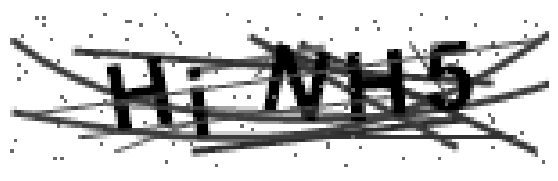

[20/152] 103617  type what you see (s=skip, q=quit):  HiNH5


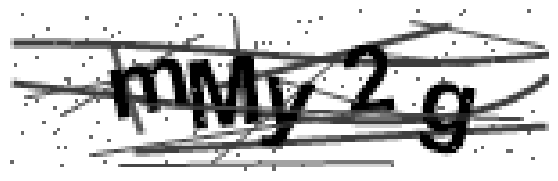

[21/152] 2805  type what you see (s=skip, q=quit):  mMy2g


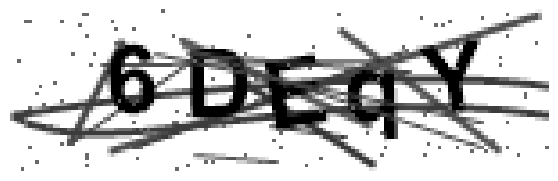

[22/152] 3064  type what you see (s=skip, q=quit):  6DEqY


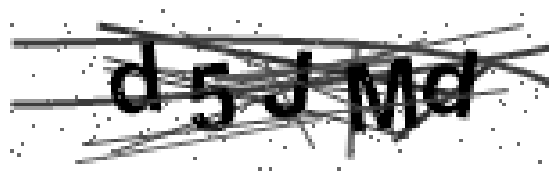

[23/152] 57710  type what you see (s=skip, q=quit):  d5JMd


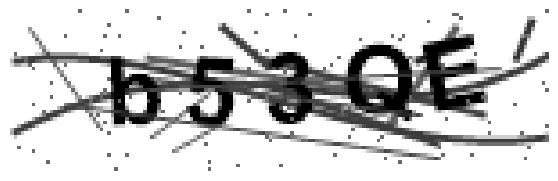

[24/152] 87708  type what you see (s=skip, q=quit):  b53QE


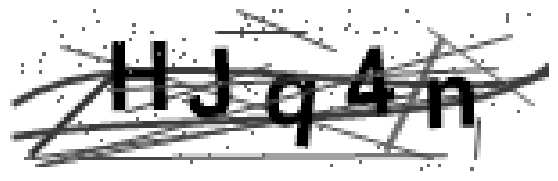

[25/152] 10573  type what you see (s=skip, q=quit):  HJq4n


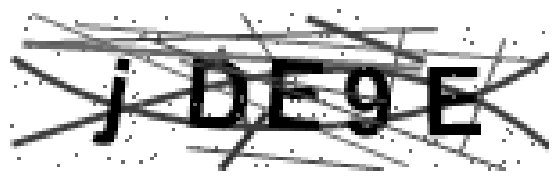

[26/152] 63069  type what you see (s=skip, q=quit):  jDE9E


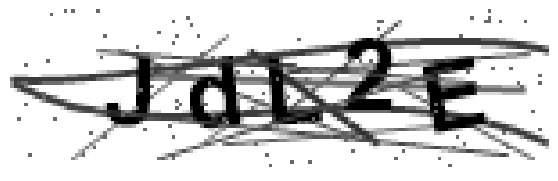

[27/152] 120613  type what you see (s=skip, q=quit):  JdL2E


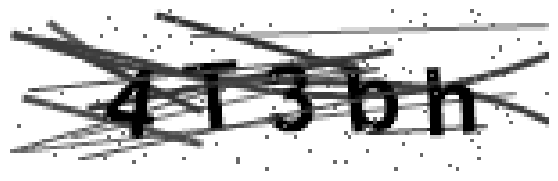

[28/152] 90051  type what you see (s=skip, q=quit):  4T3bh


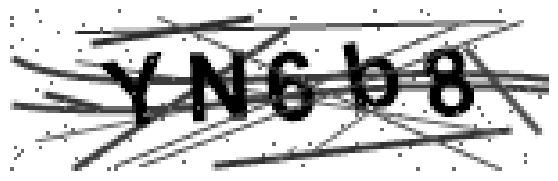

[29/152] 23357  type what you see (s=skip, q=quit):  YN6b8


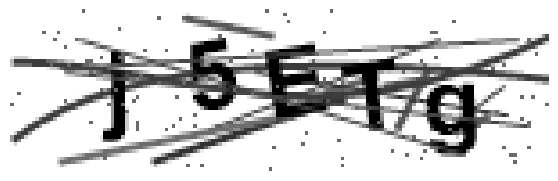

[30/152] 33157  type what you see (s=skip, q=quit):  j5ETg


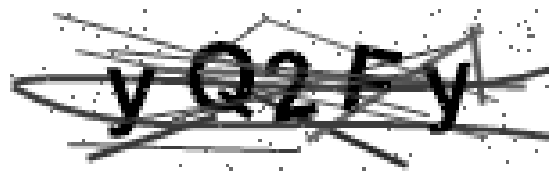

[31/152] 34489  type what you see (s=skip, q=quit):  yQ2Fy


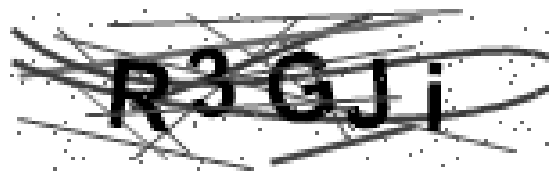

[32/152] 114100  type what you see (s=skip, q=quit):  R3GJi


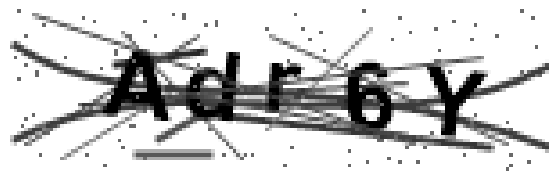

[33/152] 14793  type what you see (s=skip, q=quit):  Adr6Y


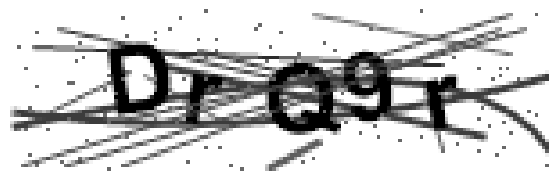

[34/152] 60575  type what you see (s=skip, q=quit):  DrQ9r


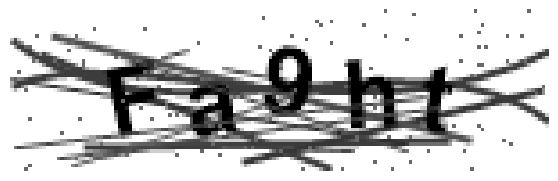

[35/152] 52224  type what you see (s=skip, q=quit):  Fa9ht


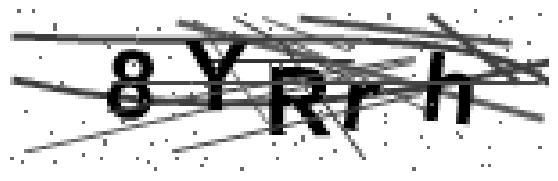

[36/152] 17833  type what you see (s=skip, q=quit):  8YRrh


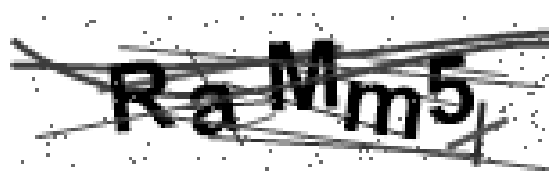

[37/152] 105647  type what you see (s=skip, q=quit):  RaMm5


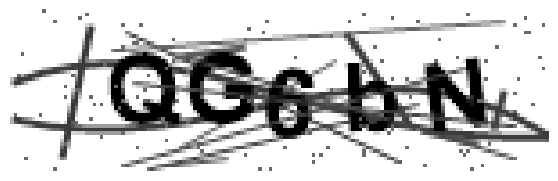

[38/152] 83085  type what you see (s=skip, q=quit):  QG6bN


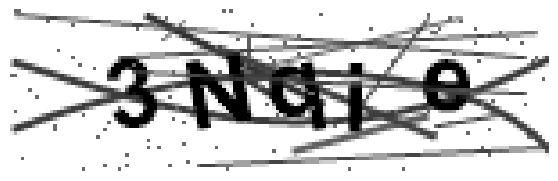

[39/152] 23290  type what you see (s=skip, q=quit):  3Nqie


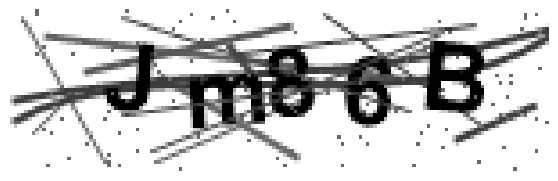

[40/152] 113577  type what you see (s=skip, q=quit):  Jm86B


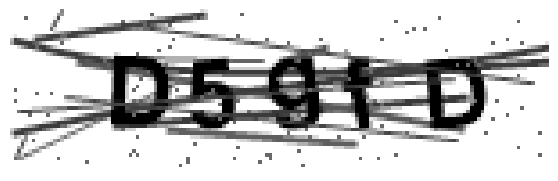

[41/152] 27695  type what you see (s=skip, q=quit):  D5gfD


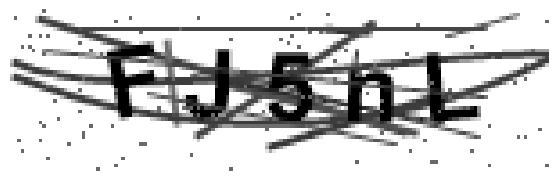

[42/152] 6321  type what you see (s=skip, q=quit):  FJ5nL


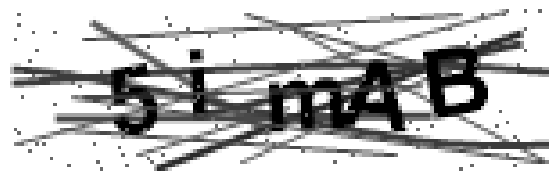

[43/152] 11431  type what you see (s=skip, q=quit):  5imAB


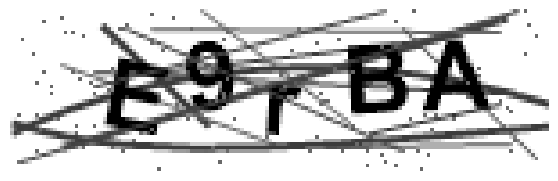

[44/152] 64244  type what you see (s=skip, q=quit):  E9rBA


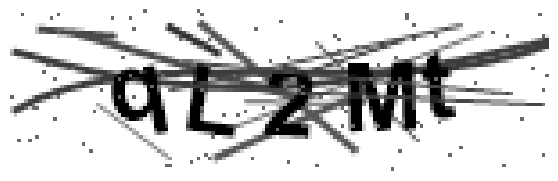

[45/152] 107568  type what you see (s=skip, q=quit):  qL2Mt


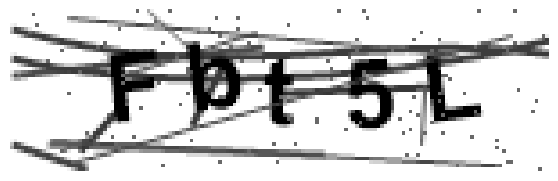

[46/152] 85820  type what you see (s=skip, q=quit):  Fbt5L


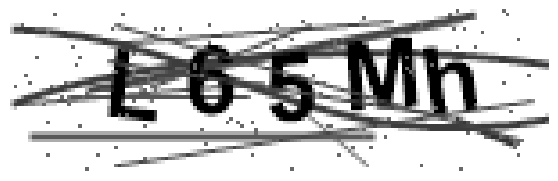

[47/152] 3317  type what you see (s=skip, q=quit):  L65Mh


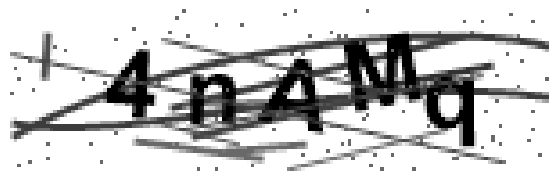

[48/152] 94919  type what you see (s=skip, q=quit):  4nAMq


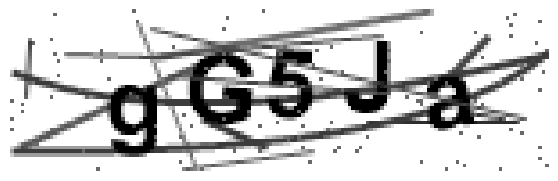

[49/152] 76552  type what you see (s=skip, q=quit):  gG5Ja


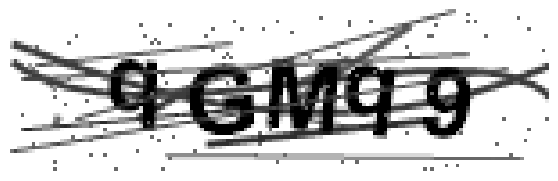

[50/152] 87563  type what you see (s=skip, q=quit):  qGMq9


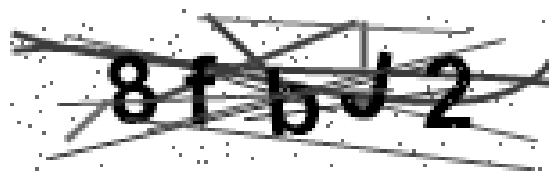

[51/152] 105901  type what you see (s=skip, q=quit):  8fbJ2


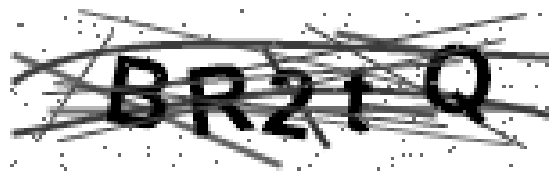

[52/152] 107913  type what you see (s=skip, q=quit):  BR2tQ


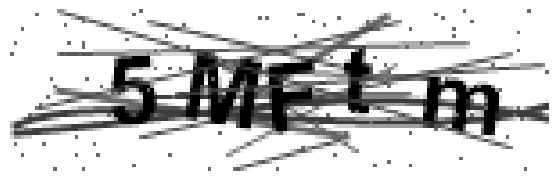

[53/152] 4101  type what you see (s=skip, q=quit):  5MFtm


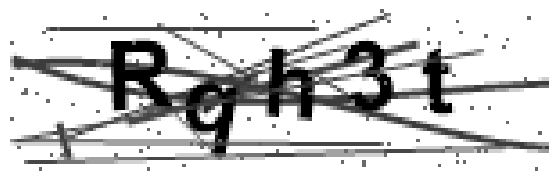

[54/152] 31610  type what you see (s=skip, q=quit):  Rqh3t


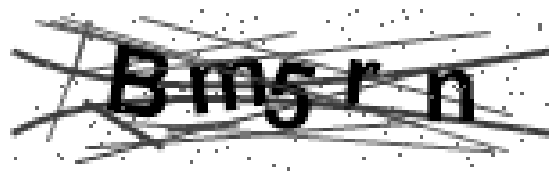

[55/152] 73122  type what you see (s=skip, q=quit):  Bm5rn


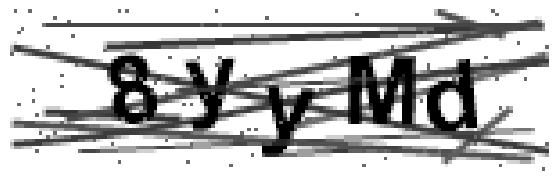

[56/152] 79123  type what you see (s=skip, q=quit):  8yyMd


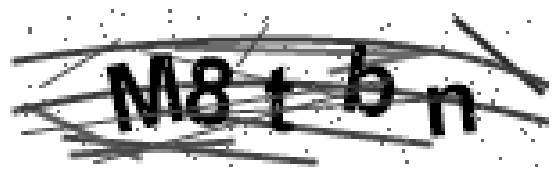

[57/152] 85795  type what you see (s=skip, q=quit):  M8tbn


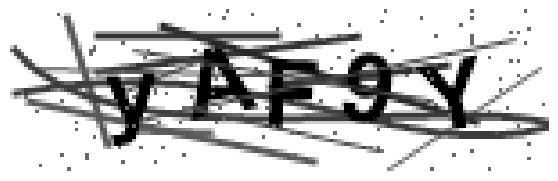

[58/152] 18511  type what you see (s=skip, q=quit):  yAF9Y


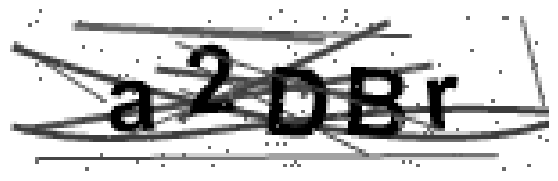

[59/152] 114738  type what you see (s=skip, q=quit):  a2DBr


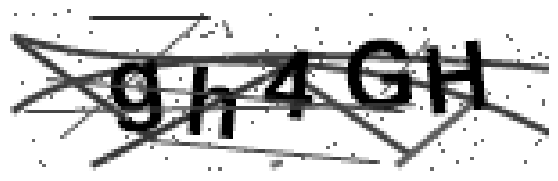

[60/152] 96046  type what you see (s=skip, q=quit):  gh4GH


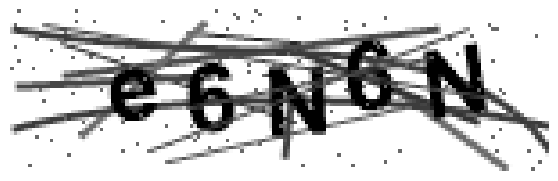

[61/152] 113979  type what you see (s=skip, q=quit):  e6N6N


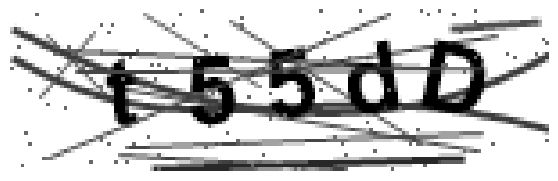

[62/152] 49662  type what you see (s=skip, q=quit):  t55dD


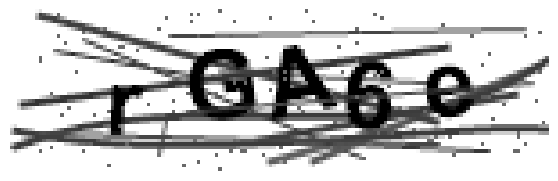

[63/152] 9934  type what you see (s=skip, q=quit):  rGA6e


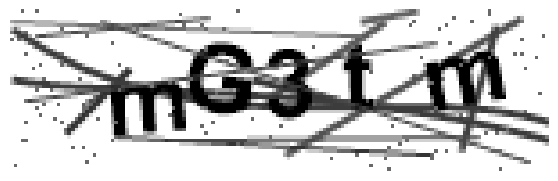

[64/152] 105201  type what you see (s=skip, q=quit):  mG3tm


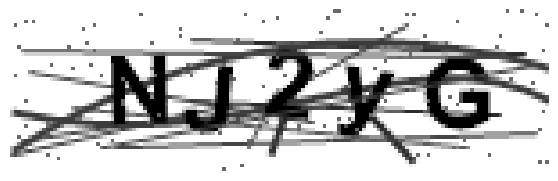

[65/152] 61986  type what you see (s=skip, q=quit):  NJ2yG


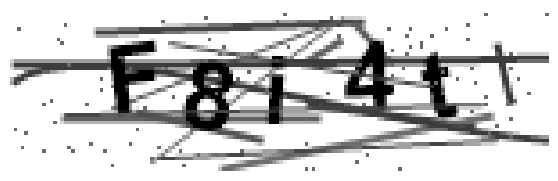

[66/152] 102144  type what you see (s=skip, q=quit):  F8i4t


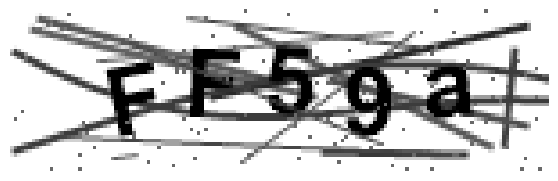

[67/152] 81383  type what you see (s=skip, q=quit):  FF59a


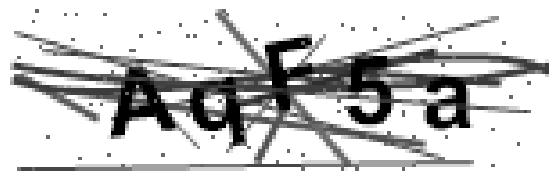

[68/152] 121323  type what you see (s=skip, q=quit):  AqF5a


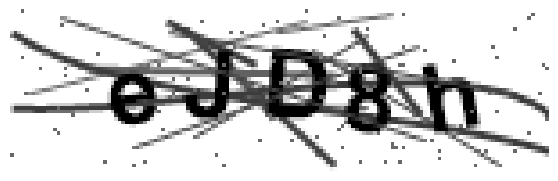

[69/152] 91630  type what you see (s=skip, q=quit):  eJD8h


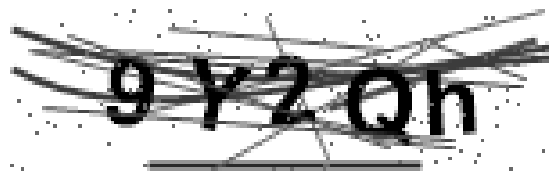

[70/152] 85787  type what you see (s=skip, q=quit):  9Y2Qh


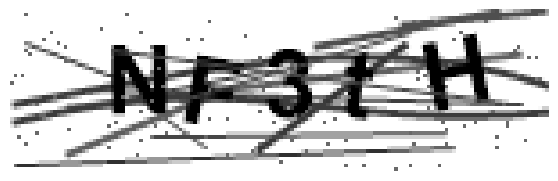

[71/152] 115933  type what you see (s=skip, q=quit):  NF3tH


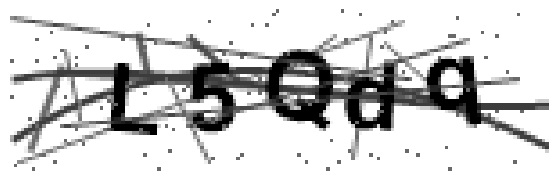

[72/152] 78361  type what you see (s=skip, q=quit):  L5Qdq


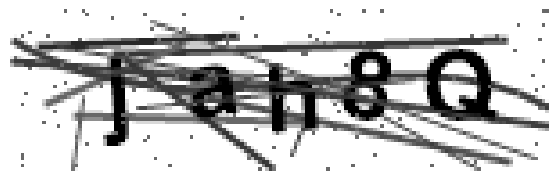

[73/152] 125600  type what you see (s=skip, q=quit):  jah8Q


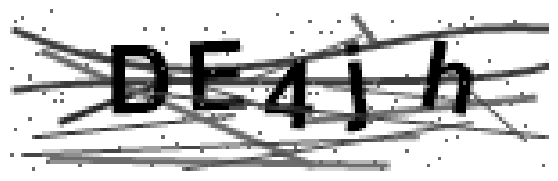

[74/152] 4725  type what you see (s=skip, q=quit):  DE4jh


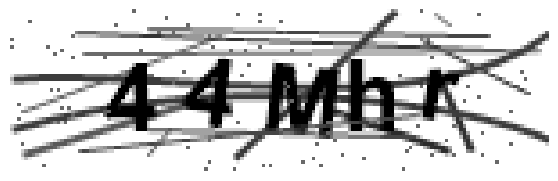

[75/152] 21161  type what you see (s=skip, q=quit):  44Mhr


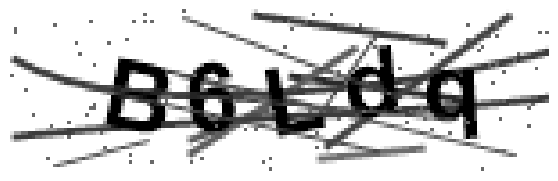

[76/152] 17864  type what you see (s=skip, q=quit):  B6Ldq


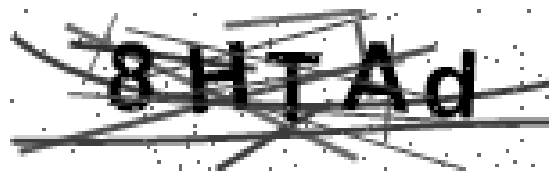

[77/152] 70021  type what you see (s=skip, q=quit):  8HTAd


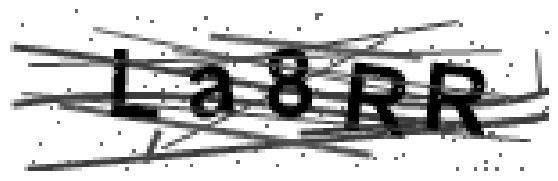

[78/152] 40581  type what you see (s=skip, q=quit):  La8RR


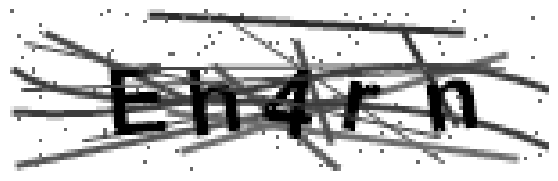

[79/152] 108085  type what you see (s=skip, q=quit):  Eh4rn


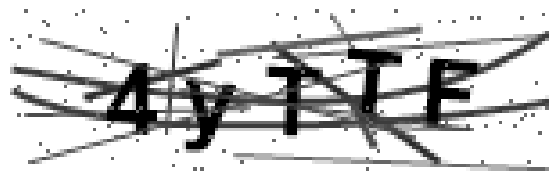

[80/152] 8146  type what you see (s=skip, q=quit):  4yTTF


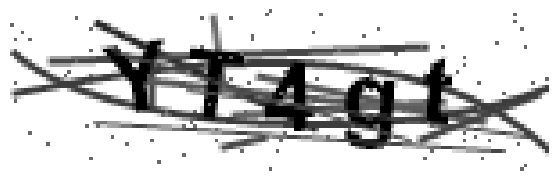

[81/152] 52646  type what you see (s=skip, q=quit):  YT4gt


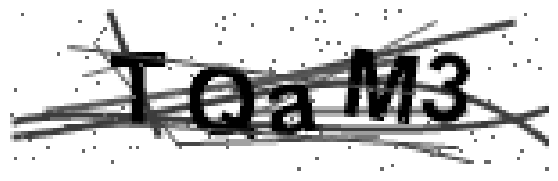

[82/152] 26353  type what you see (s=skip, q=quit):  TQaM3


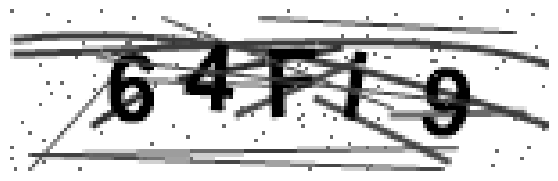

[83/152] 111217  type what you see (s=skip, q=quit):  64Fi9


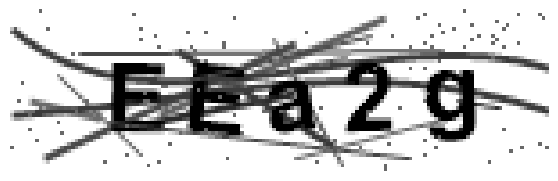

[84/152] 64545  type what you see (s=skip, q=quit):  EEa2g


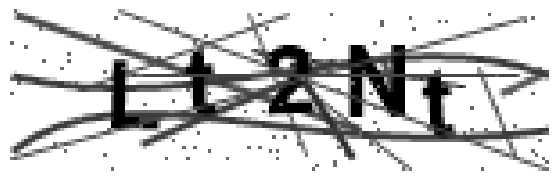

[85/152] 30798  type what you see (s=skip, q=quit):  Lt2Nt


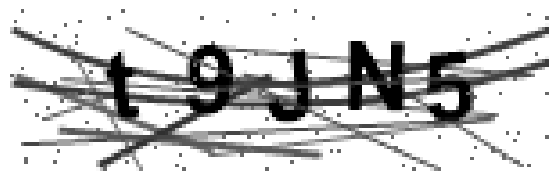

[86/152] 124994  type what you see (s=skip, q=quit):  t9JN5


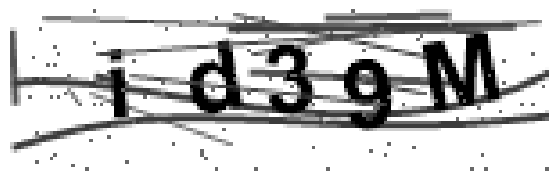

[87/152] 13887  type what you see (s=skip, q=quit):  id39M


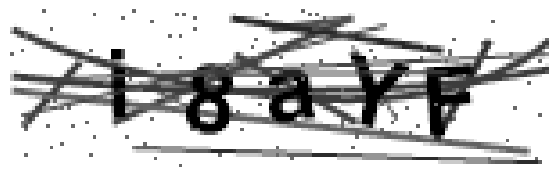

[88/152] 33293  type what you see (s=skip, q=quit):  i8aYF


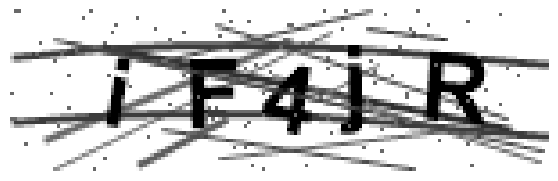

[89/152] 101867  type what you see (s=skip, q=quit):  iF4jR


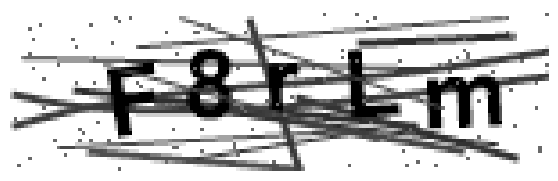

[90/152] 124121  type what you see (s=skip, q=quit):  F8rLm


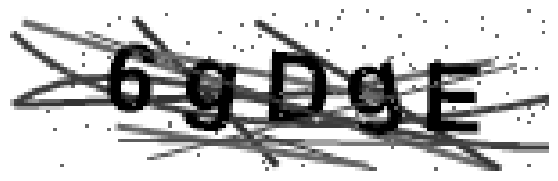

[91/152] 50194  type what you see (s=skip, q=quit):  6gDgE


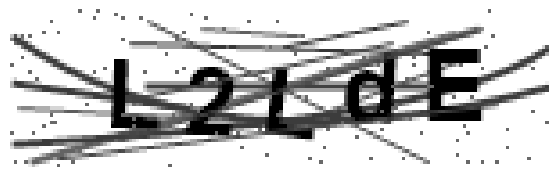

[92/152] 7934  type what you see (s=skip, q=quit):  L2LdE


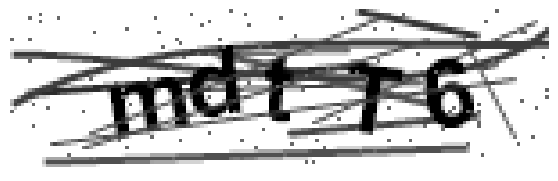

[93/152] 99107  type what you see (s=skip, q=quit):  mdtT6


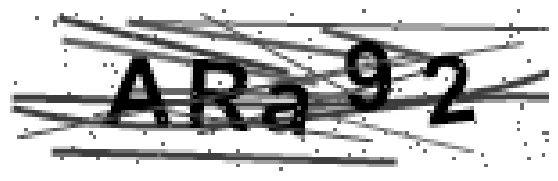

[94/152] 41003  type what you see (s=skip, q=quit):  ARa92


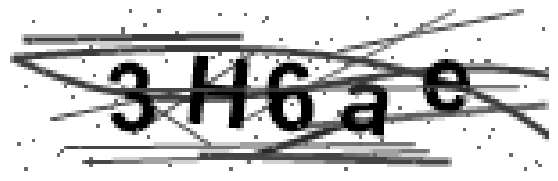

[95/152] 65451  type what you see (s=skip, q=quit):  3H6ae


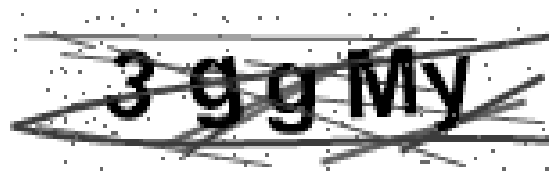

[96/152] 38172  type what you see (s=skip, q=quit):  3ggMy


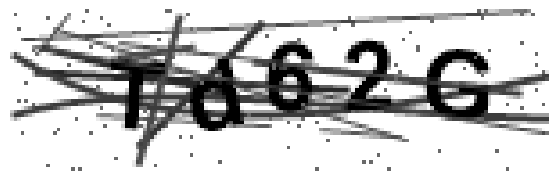

[97/152] 3365  type what you see (s=skip, q=quit):  Td62G


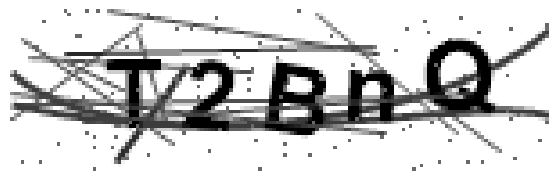

[98/152] 96894  type what you see (s=skip, q=quit):  T2BnQ


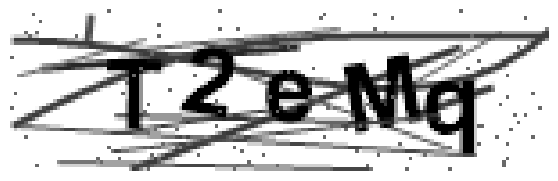

[99/152] 105304  type what you see (s=skip, q=quit):  T2eMq


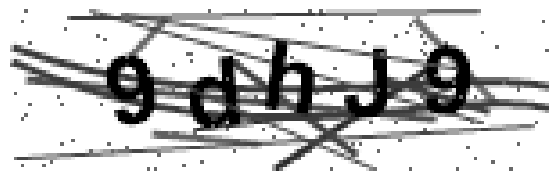

[100/152] 18741  type what you see (s=skip, q=quit):  9dhJ9


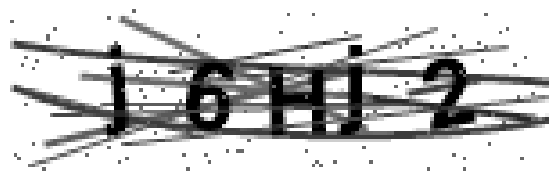

[101/152] 11186  type what you see (s=skip, q=quit):  j6Hj2


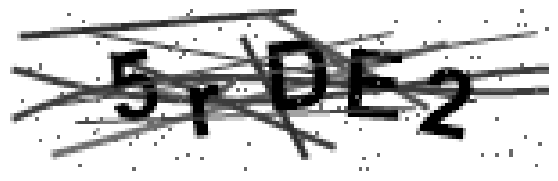

[102/152] 26410  type what you see (s=skip, q=quit):  5rDE2


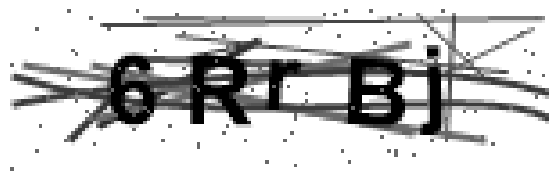

[103/152] 102259  type what you see (s=skip, q=quit):  6RrBj


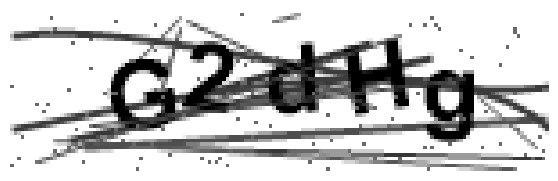

[104/152] 35088  type what you see (s=skip, q=quit):  G2dHg


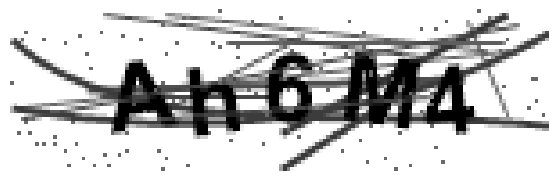

[105/152] 17684  type what you see (s=skip, q=quit):  Ah6M4


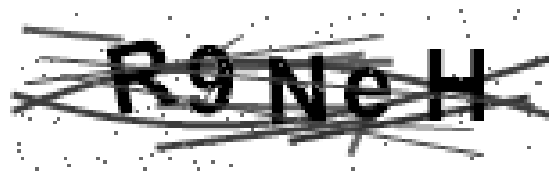

[106/152] 69529  type what you see (s=skip, q=quit):  R9NeH


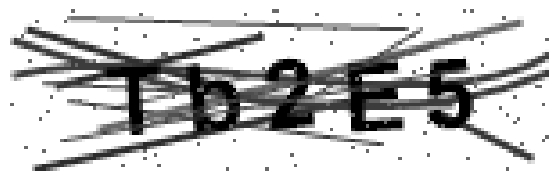

[107/152] 116640  type what you see (s=skip, q=quit):  Tb2E5


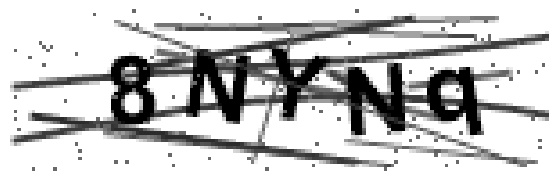

[108/152] 51428  type what you see (s=skip, q=quit):  8NYNq


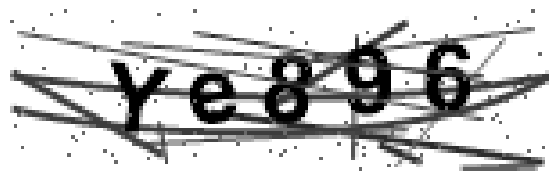

[109/152] 9856  type what you see (s=skip, q=quit):  Ye896


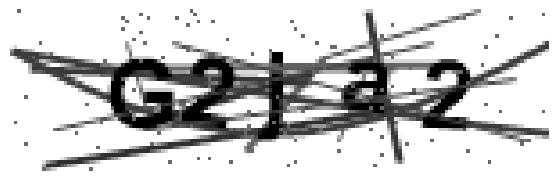

[110/152] 24950  type what you see (s=skip, q=quit):  G2ja2


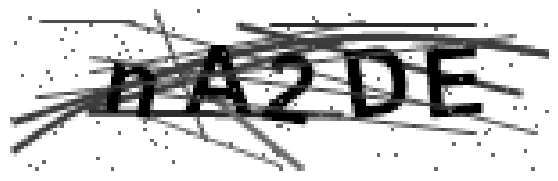

[111/152] 112971  type what you see (s=skip, q=quit):  nA2DE


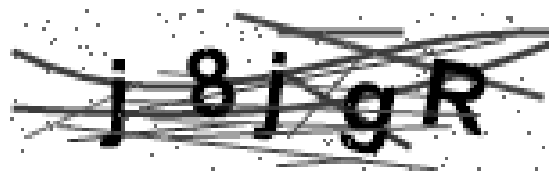

[112/152] 64501  type what you see (s=skip, q=quit):  j8jgR


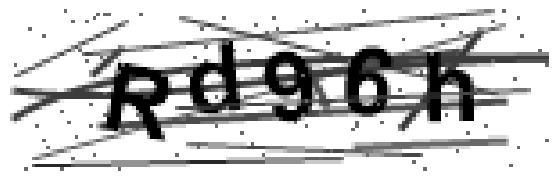

[113/152] 73176  type what you see (s=skip, q=quit):  Rd96h


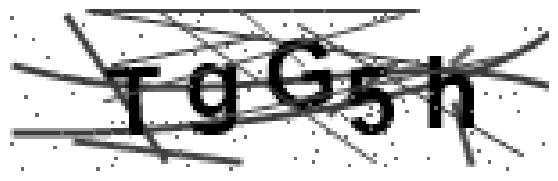

[114/152] 18906  type what you see (s=skip, q=quit):  TgG5h


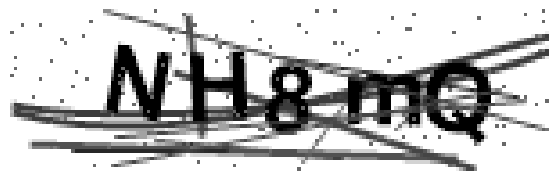

[115/152] 17272  type what you see (s=skip, q=quit):  NH8mQ


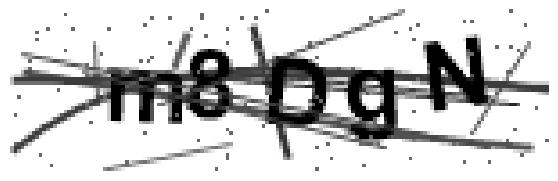

[116/152] 56278  type what you see (s=skip, q=quit):  m8DgN


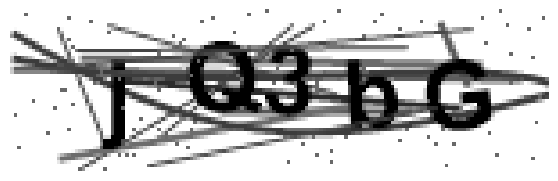

[117/152] 81206  type what you see (s=skip, q=quit):  jQ3bG


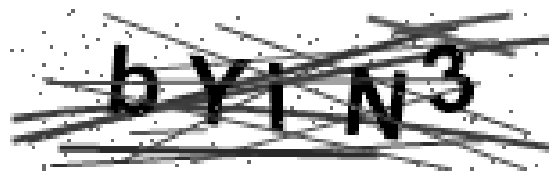

[118/152] 98435  type what you see (s=skip, q=quit):  bYiN3


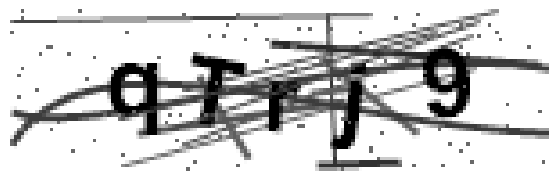

[119/152] 15889  type what you see (s=skip, q=quit):  qTrj9


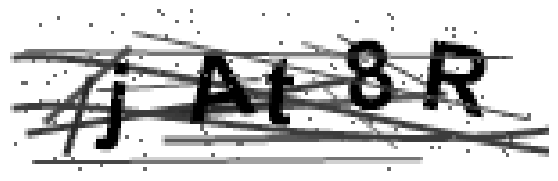

[120/152] 123884  type what you see (s=skip, q=quit):  jAt8R


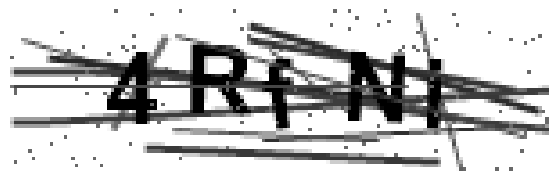

[121/152] 40421  type what you see (s=skip, q=quit):  4RfNi


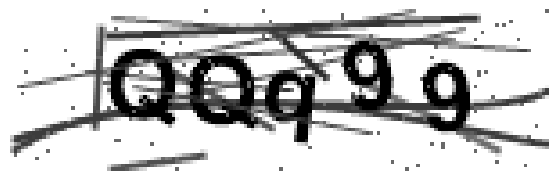

[122/152] 77838  type what you see (s=skip, q=quit):  QQq99


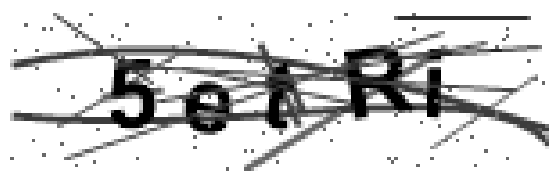

[123/152] 120811  type what you see (s=skip, q=quit):  5etRi


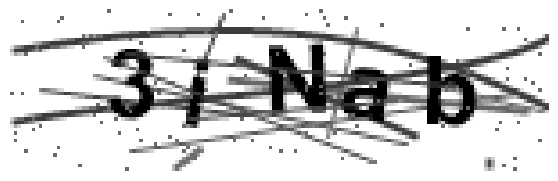

[124/152] 54120  type what you see (s=skip, q=quit):  3iNab


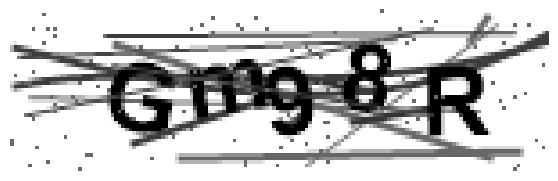

[125/152] 59740  type what you see (s=skip, q=quit):  Gmg8R


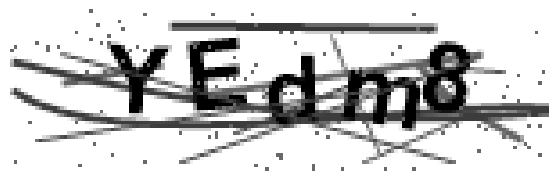

[126/152] 76853  type what you see (s=skip, q=quit):  YEdm8


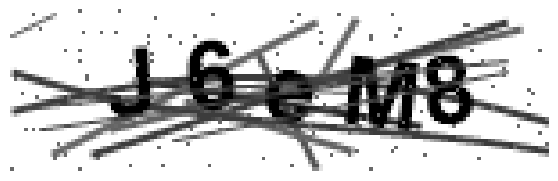

[127/152] 89479  type what you see (s=skip, q=quit):  J6eM8


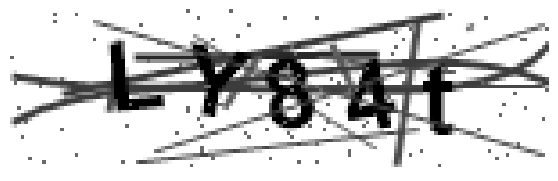

[128/152] 102466  type what you see (s=skip, q=quit):  LY84t


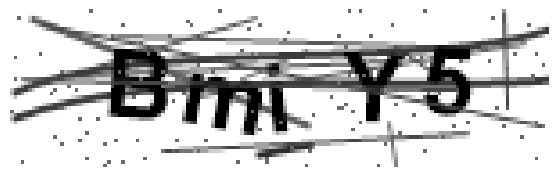

[129/152] 13029  type what you see (s=skip, q=quit):  BmiY5


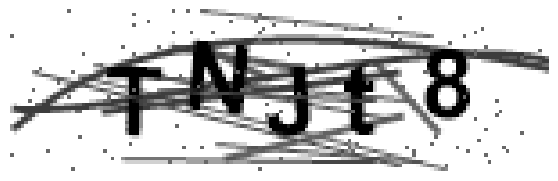

[130/152] 46806  type what you see (s=skip, q=quit):  TNJt8


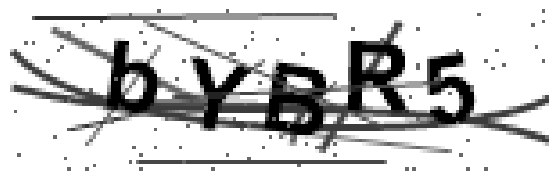

[131/152] 43762  type what you see (s=skip, q=quit):  bYBR5


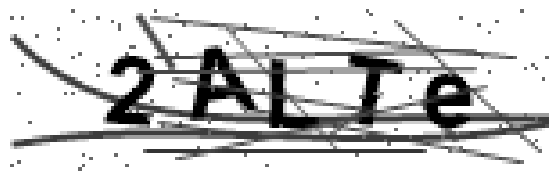

[132/152] 61838  type what you see (s=skip, q=quit):  2ALTe


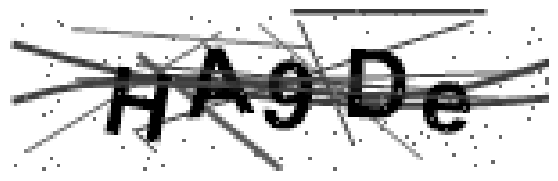

[133/152] 117184  type what you see (s=skip, q=quit):  HA9De


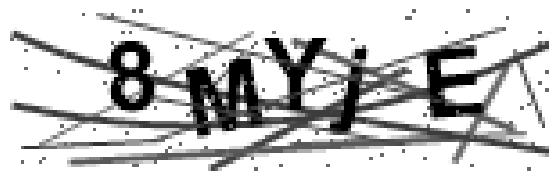

[134/152] 86938  type what you see (s=skip, q=quit):  8MYjE


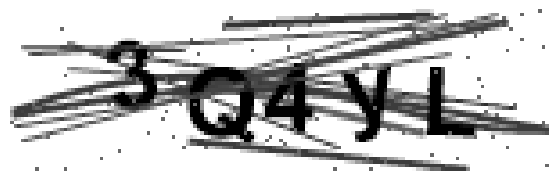

[135/152] 80444  type what you see (s=skip, q=quit):  3Q4yL


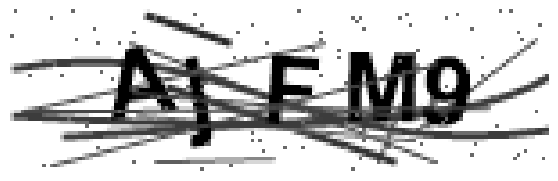

[136/152] 112428  type what you see (s=skip, q=quit):  AjFM9


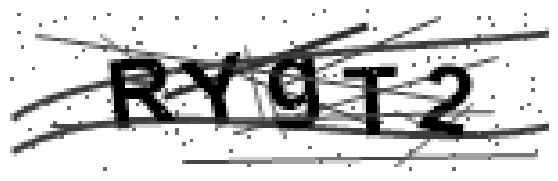

[137/152] 122184  type what you see (s=skip, q=quit):  RYgT2


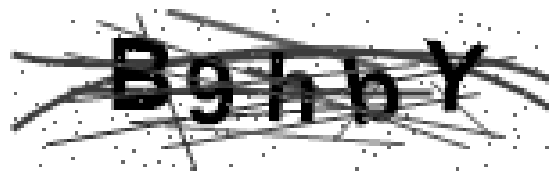

[138/152] 40461  type what you see (s=skip, q=quit):  B9hbY


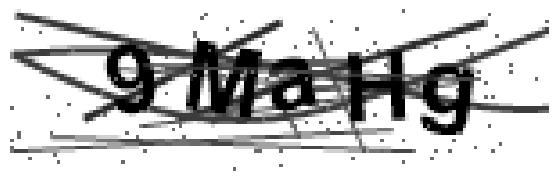

[139/152] 21158  type what you see (s=skip, q=quit):  9MaHg


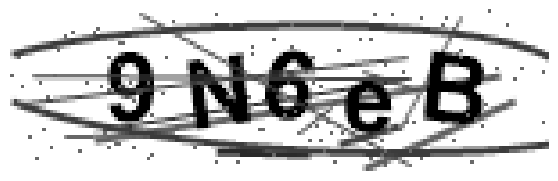

[140/152] 37936  type what you see (s=skip, q=quit):  9N6eB


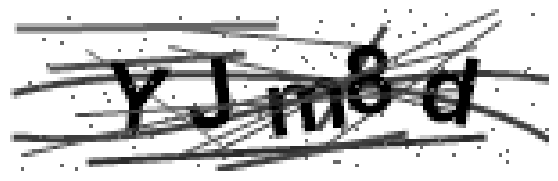

[141/152] 106635  type what you see (s=skip, q=quit):  YJm8d


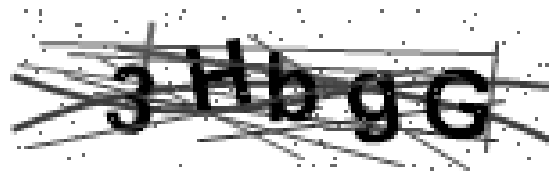

[142/152] 71461  type what you see (s=skip, q=quit):  3HbgG


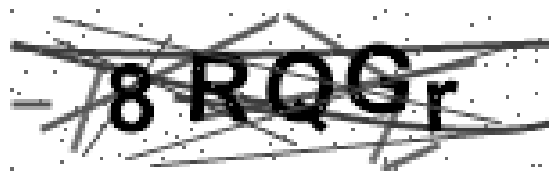

[143/152] 77759  type what you see (s=skip, q=quit):  8RQGr


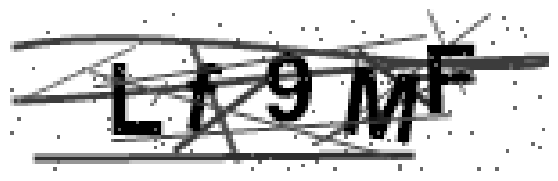

[144/152] 91531  type what you see (s=skip, q=quit):  Lf9MF


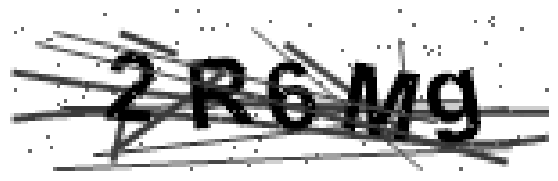

[145/152] 13924  type what you see (s=skip, q=quit):  2R6Mg


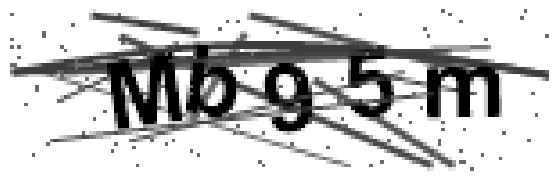

[146/152] 91535  type what you see (s=skip, q=quit):  Mbg5m


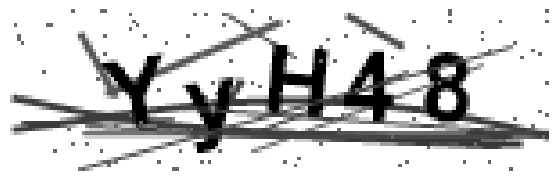

[147/152] 109453  type what you see (s=skip, q=quit):  YyH48


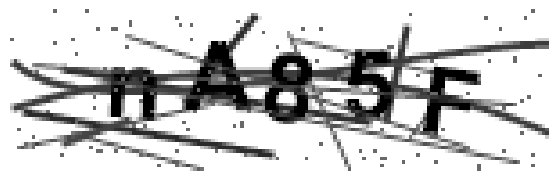

[148/152] 73737  type what you see (s=skip, q=quit):  nA85F


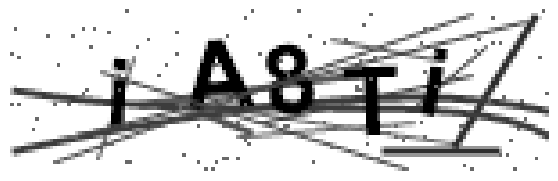

[149/152] 11779  type what you see (s=skip, q=quit):  iA8Ti


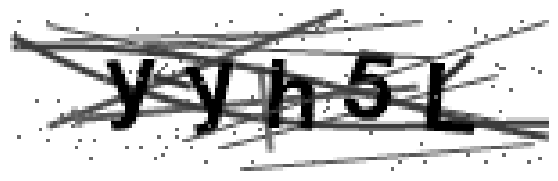

[150/152] 83962  type what you see (s=skip, q=quit):  yyh5l


  need 5 characters from 2345689ABDEFGHJLMNQRTYabdefghijmnqrty (exact case), try again


[150/152] 83962  type what you see (s=skip, q=quit):  yyh5L


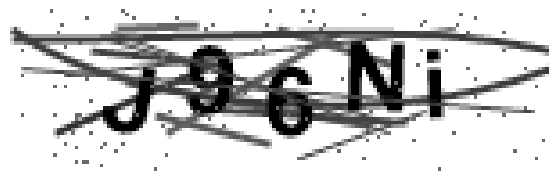

[151/152] 111285  type what you see (s=skip, q=quit):  J96Ni


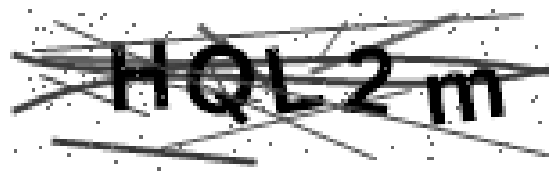

[152/152] 110814  type what you see (s=skip, q=quit):  HQL2m



step 2: your blind answers match gold on 144/152; 8 to resolve


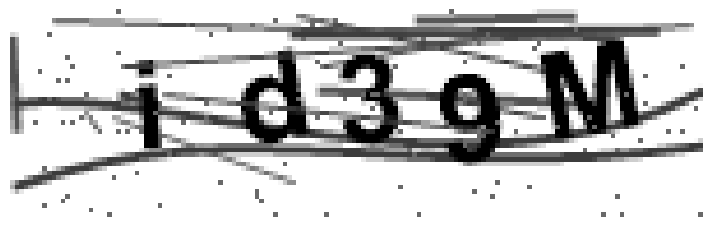

[1/8] 13887  1 = gold id3gM   2 = new id39M   (@3: g vs 9)   or type the answer:  id39M


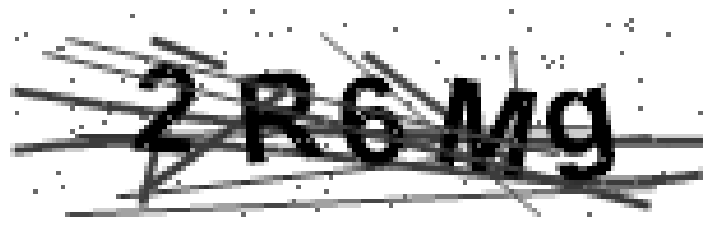

[2/8] 13924  1 = gold 2R6M9   2 = new 2R6Mg   (@4: 9 vs g)   or type the answer:  2R6Mg


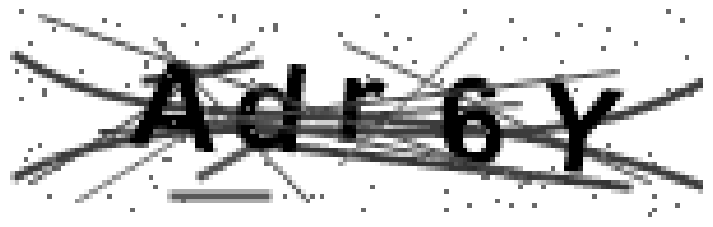

[3/8] 14793  1 = gold Adr6y   2 = new Adr6Y   (@4: y vs Y)   or type the answer:  Adr6Y


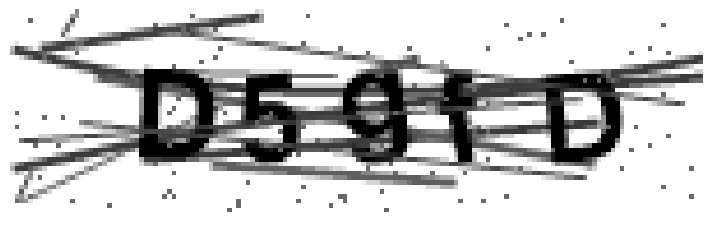

[4/8] 27695  1 = gold D59fD   2 = new D5gfD   (@2: 9 vs g)   or type the answer:  D5gfD


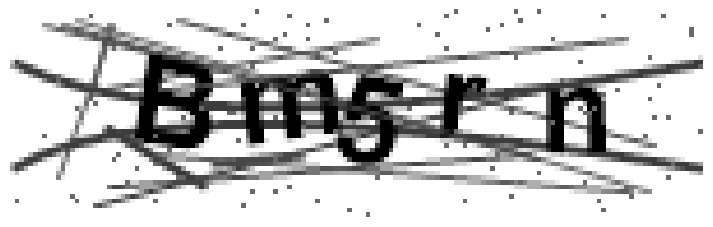

[5/8] 73122  1 = gold Dm5rn   2 = new Bm5rn   (@0: D vs B)   or type the answer:  Bm5rn


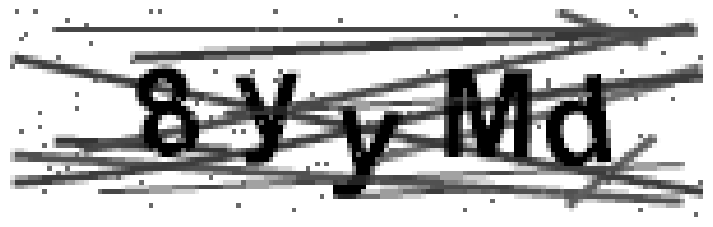

[6/8] 79123  1 = gold 8YyMd   2 = new 8yyMd   (@1: Y vs y)   or type the answer:  8yyMd


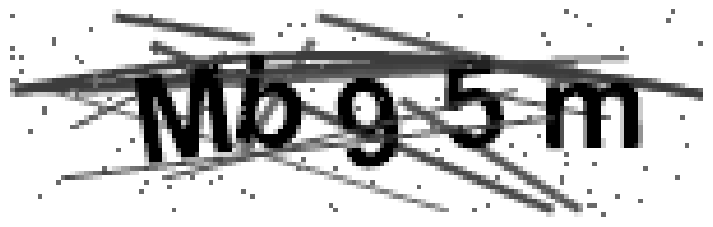

[7/8] 91535  1 = gold Mb95m   2 = new Mbg5m   (@2: 9 vs g)   or type the answer:  Mb95m


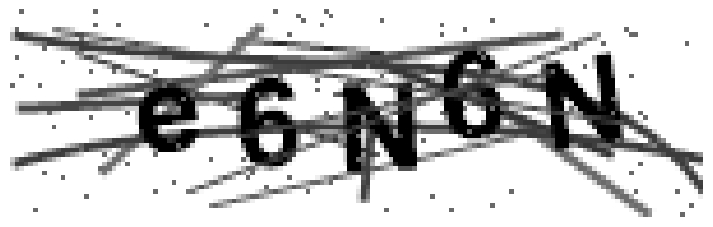

[8/8] 113979  1 = gold e6NGN   2 = new e6N6N   (@3: G vs 6)   or type the answer:  e6N6N



7 gold labels corrected (original kept as ../data/gold_before_audit.csv):
  13887: id3gM -> id39M
  13924: 2R6M9 -> 2R6Mg
  14793: Adr6y -> Adr6Y
  27695: D59fD -> D5gfD
  73122: Dm5rn -> Bm5rn
  79123: 8YyMd -> 8yyMd
  113979: e6NGN -> e6N6N
gold split refreshed: re-run the test cell (9) to see the corrected scores


In [11]:
%run -i ../scripts/audit_gold.py

## 11. Review the model's least confident reads (run as many times as you like)
Enter = right, type the truth if wrong, s = skip, q = quit. Settings (N_REVIEW, FOCUS) at the top of `../scripts/review.py`.
Reviews add to `../data/reviews.json` (shared with round 1).

In [ ]:
%run -i ../scripts/review.py

## 12. Fine-tune the baseline on all reviews → `models/captcha_cnn_v2_ft.pt` (run once, after reviewing)

In [ ]:
%run -i ../scripts/finetune.py

## 13. What the fine-tune fixed and broke on gold (vs the new baseline)

In [ ]:
base_model, _ = load_model(MODEL_PATH)
p_base, p_ft, y = predict(base_model, "gold"), predict(ft_model, "gold"), data["gold"][1]
for k, r in enumerate(split_rows["gold"]):
    b, f = torch.equal(p_base[k], y[k]), torch.equal(p_ft[k], y[k])
    if b != f:
        print(f"{'FIXED ' if f else 'BROKEN'} {r['id']}  true {r['label']}  "
              f"baseline {decode_pred(p_base[k].tolist())}  fine-tuned {decode_pred(p_ft[k].tolist())}")